# Munich rents: investigation of a construction-year reversal

This case uses the public mboostrs search actions to predict **monthly net rent** for apartments in Munich districts that were not used to build the model. The practical output is a fitted rent prediction for a described apartment. The analytical question is whether the construction-year curve needs an apparent premium for the oldest buildings, and whether an observed variable explains that departure from a rent that otherwise rises with newer construction. The data are a 1999 survey, so the predictions describe 1999 rents. The [`rent99` documentation](https://search.r-project.org/CRAN/refmans/gamlss.data/html/rent99.html) defines rent in euros, area in square metres, `cheating` as central heating, `bath` and `kitchen` as indicators of above-standard (premium) bathroom and kitchen fittings, and location as an ordered quality grade (average, good, top).

Each search action was chosen after reading the training-only outputs of the previous actions. The page replays those choices with fixed seeds; **no language model makes decisions on this page**. The sections from "Data and district split" to "Area and construction-year shapes" reach a tuned prediction; the sections from "Extension: investigating the year curve" onward examine the year curve. The [search methodology](../methodology/search_decisions.ipynb) explains the paired-fold rule and why its standard errors remain descriptive after search.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | Monthly net rent for an apartment in a district not used to fit or choose the model. |
| **Observed response** | `rent`, euros per month. `rentsqm` is excluded because it contains `rent` divided by area. |
| **Estimand** | A conditional mean prediction for the listed apartment characteristics, not an effect of changing construction year or amenities. |
| **Sampling unit** | One surveyed apartment; 3,082 apartments in 336 districts. |
| **Dependence** | Apartments within a district may share unmeasured location and housing conditions. |
| **Split / resampling unit** | Entire district; 269 districts (2,465 apartments) for development and 67 districts (617 apartments) for one final test. |
| **Tuning** | Five grouped folds within development data choose boosting iterations by response-scale MSE; candidates use the same folds. |
| **Uncertainty** | Paired fold standard errors describe development-fold variation, not post-search confidence intervals. One district holdout supplies a predictive check. |
| **Claim type** | Predictive comparison and descriptive shape analysis; no causal or contemporary price claim. |
:::

The decision path is: screen measured predictors → fit and tune a linear baseline → compare smooth shapes → inspect the chosen model → test explanations for the year-curve dip → simplify → score untouched districts once. Every comparison is paired: each candidate and the current model are scored on the same five district folds, and the five per-fold differences give a mean change and its standard error (the paired SE). A candidate enters the model only when it reduces the fold error by more than two paired SEs, or when a smaller specification increases it by less than two paired SEs. These thresholds are preferences of the search and carry no hypothesis-test error rate; the size of a gain and the observed support of the predictors still matter.

## Data and district split

The bundled survey records construction year, floor area, location quality, bathroom and kitchen quality, central heating, and district. Districts are divided into development and test sets before any screen that reads the response. The indicator `old_1918` marks apartments whose recorded `yearc` equals 1918, a value that occurs unusually often; it is derived from the *predictor* `yearc` alone and represents a possible recorded code. `district` defines the folds and the split. It is not used as a predictor, because the test districts are absent from training.

In [1]:
import math
import numpy as np
import polars as pl
import altair as alt
from IPython.display import display
import mboostrs as mb
from bench_tables import table

alt.renderers.enable("svg")
raw = mb.datasets.munich_rent(output="polars")
outer = np.asarray(mb.grouped_folds(
    np.asarray(raw["district"].to_list()), B=5, seed=29))[:, 0]
frame = raw.with_columns(
    (pl.col("location") == 2).cast(pl.Int64).alias("good_location"),
    (pl.col("location") == 3).cast(pl.Int64).alias("top_location"),
    (pl.col("yearc") == 1918).cast(pl.Int64).alias("old_1918"),
).select("rent", "area", "yearc", "old_1918", "good_location",
         "top_location", "bath", "kitchen", "cheating", "district")
train = frame.filter(pl.Series(outer != 0))
test = frame.filter(pl.Series(outer == 0))
print(f"Development: {train.height} apartments, {train['district'].n_unique()} districts")
print(f"Reserved test: {test.height} apartments, {test['district'].n_unique()} districts")

Development: 2465 apartments, 269 districts
Reserved test: 617 apartments, 67 districts


## Training-only screening

`open_search` fixes Gaussian mean prediction, response-scale squared error and five district folds; `mb.CostBudget(fits=400)` caps the number of model fits that all actions of the search together may use. Floor area should increase monthly rent; construction year may stand for changing building quality and period; the location grade and amenities are measured predictors, while district is a cluster label. The marginal screen fits each predictor alone. The dual pre-scan fits a boosted-tree ensemble and a small neural network to all predictors and ranks predictors and pairs by their importance in those fits. Both propose terms to test; neither adopts a specification. The marginal association scores do not adjust for the other predictors.

In [2]:
session = mb.open_search(
    train, "rent", family=mb.Gaussian(), score="mse",
    groups="district", folds=5, seed=31, mstop=100, nu=.3,
    budget=mb.CostBudget(fits=400),
)
session.run("hypothesis", variable="area", role="apartment size",
    statement="Larger apartments should usually have higher monthly rent.",
    would_count_against="A constrained or linear size term predicts materially worse than a flexible alternative.")
session.run("classify")
screen = session.run("column_screen", columns=[
    "area", "yearc", "good_location", "top_location", "bath", "kitchen", "cheating",
])
screen_rows = pl.DataFrame([{
    "variable": row["column"], "linear_r2": row["linear_r2"],
    "curve_r2": row["curve_r2"], "hint": row["hint"],
} for row in screen.value])
display(table(screen_rows, title="Marginal training associations",
    subtitle="Unadjusted R², dimensionless; larger is stronger, not necessarily causal",
    stub="variable", stubhead="Predictor", better={"linear_r2": "max", "curve_r2": "max"},
    labels={"linear_r2": "Linear R²", "curve_r2": "Curve R²", "hint": "Shape hint"},
    notes=("The screen uses development apartments only; correlated predictors can share signal.",)))

GT(_tbl_data=shape: (7, 4)
┌───────────────┬───────────┬──────────┬──────┐
│ variable      ┆ linear_r2 ┆ curve_r2 ┆ hint │
│ ---           ┆ ---       ┆ ---      ┆ ---  │
│ str           ┆ f64       ┆ f64      ┆ str  │
╞═══════════════╪═══════════╪══════════╪══════╡
│ area          ┆ 0.348379  ┆ 0.339559 ┆ line │
│ yearc         ┆ 0.013548  ┆ 0.086282 ┆ step │
│ bath          ┆ 0.058423  ┆ 0.058041 ┆ line │
│ kitchen       ┆ 0.0333    ┆ 0.032907 ┆ line │
│ top_location  ┆ 0.018041  ┆ 0.017642 ┆ line │
│ good_location ┆ 0.008773  ┆ 0.00837  ┆ none │
│ cheating      ┆ 0.054448  ┆ 0.0      ┆ none │
└───────────────┴───────────┴──────────┴──────┘, _body=<great_tables._gt_data.Body object at 0x10cb05760>, _boxhead=Boxhead([ColInfo(var='variable', type=<ColInfoTypeEnum.stub: 2>, column_label='variable', column_align='left', column_width=None, stub_level=0), ColInfo(var='linear_r2', type=<ColInfoTypeEnum.default: 1>, column_label='Linear R²', column_align='right', column_width=None, stub_level=None), ColInfo(var='curve_r2', type=<ColInfoTypeEnum.default: 1>, column_label='Curve R²', column_align='right', column_width=None, stub_level=None), ColInfo(var='hint', type=<ColInfoTypeEnum.default: 1>, column_label='Shape hint', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10d7a6000>, _spanners=Spanners([]), _heading=Heading(title='Marginal training associations', subtitle='Unadjusted R², dimensionless; larger is stronger, not necessarily causal', preheader=None), _stubhead='Predictor', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10d7812e0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10d781700>, _source_notes=['The screen uses development apartments only; correlated predictors can share signal.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10afceb10>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10d781010>, <great_tables._gt_data.FormatInfo object at 0x10afed010>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10d82bb60>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), tabl

In [3]:
scan = session.run("pre_scan", engine="dual", rounds=100)
print("Dual pre-scan priority:", scan.summary["priority"][:7])
print("Area–year pair proposed by:", next(
    row["sources"] for row in scan.summary["pair_sources"]
    if row["columns"] == ["area", "yearc"]
))
print("Native fits charged:", scan.fit_charges)

Dual pre-scan priority: ['area', 'yearc', 'district', 'cheating', 'old_1918', 'kitchen', 'good_location']
Area–year pair proposed by: ['tree']
Native fits charged: 2


Area is the strongest marginal predictor (linear R² about 0.35); year has little linear association (R² about 0.014) but a larger curved/step association (about 0.086). The tree part of the pre-scan also proposes an area–year interaction. It ranks district highly, but district codes are identifiers and the target is a new district; its fitted effect would not identify an unseen district's rent. The comparisons that follow test area and year shapes directly; the pre-scan ranking only orders the candidates.

## Linear baseline and first prediction

`bols` fits a linear component for area and year and indicator components for location and amenities. `tune` selects the boosting iteration by five development-district folds, refits on all development apartments, and retains that model. The baseline remains fixed for the final district test.

In [4]:
linear = ("bols(area) + bols(yearc) + bols(good_location) "
          "+ bols(top_location) + bols(bath) + bols(kitchen) "
          "+ bols(cheating)")
session.run("set_spec", rhs=linear)
baseline_tuning = session.run("tune", start=100)
baseline_model = session.model
print("Linear baseline mstop:", baseline_tuning.summary["mstop"])
print("Fits charged by tuning:", baseline_tuning.fit_charges)

Linear baseline mstop: 83
Fits charged by tuning: 6


## Area and construction-year shapes

Three revisions of the linear baseline are compared at the same 100-iteration limit on the same development folds. A negative change is a reduction in mean squared error (MSE, euros²) relative to the baseline. `bbs` replaces a linear term with a penalized B-spline smooth; whether the fitted shape is stable or causal needs separate checks.

In [5]:
smooth_year = linear.replace("bols(yearc)", "bbs(yearc)")
shapes = session.run("compare", mstop=100, candidates={
    "smooth year": smooth_year,
    "smooth area": linear.replace("bols(area)", "bbs(area)"),
    "both smooth": smooth_year.replace("bols(area)", "bbs(area)"),
})
shape_rows = pl.DataFrame([{
    "candidate": row["specification"], "mse": row["out-of-fold risk"],
    "change": row["change"], "se": row["change se"],
} for row in shapes.value])
display(table(shape_rows, title="Initial shape comparison",
    subtitle="District-fold MSE and paired change, euros²; lower is better",
    stub="candidate", stubhead="Specification", better={"mse": "min"},
    labels={"mse": "MSE", "change": "Change", "se": "Paired SE"},
    decimals=1, notes=("Change = candidate minus linear baseline at 100 iterations.",
                       "SE uses five shared development folds and is descriptive after candidate search.")))

GT(_tbl_data=shape: (4, 4)
┌─────────────┬──────────────┬─────────────┬────────────┐
│ candidate   ┆ mse          ┆ change      ┆ se         │
│ ---         ┆ ---          ┆ ---         ┆ ---        │
│ str         ┆ f64          ┆ f64         ┆ f64        │
╞═════════════╪══════════════╪═════════════╪════════════╡
│ current     ┆ 19600.060068 ┆ 0.0         ┆ 0.0        │
│ smooth year ┆ 18626.03535  ┆ -974.024718 ┆ 173.29576  │
│ smooth area ┆ 19735.47783  ┆ 135.417762  ┆ 68.854017  │
│ both smooth ┆ 18707.976306 ┆ -892.083763 ┆ 193.135544 │
└─────────────┴──────────────┴─────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10c78b230>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None, stub_level=0), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='Change', column_align='right', column_width=None, stub_level=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10cb39100>, _spanners=Spanners([]), _heading=Heading(title='Initial shape comparison', subtitle='District-fold MSE and paired change, euros²; lower is better', preheader=None), _stubhead='Specification', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10db0e390>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db0e810>, _source_notes=['Change = candidate minus linear baseline at 100 iterations.', 'SE uses five shared development folds and is descriptive after candidate search.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10db0cb60>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10db0c260>, <great_tables._gt_data.FormatInfo object at 0x10db0e3f0>, <great_tables._gt_data.FormatInfo object at 0x10db0c7d0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10db0e210>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category

The smooth-year candidate reduces fold MSE by about 974 ± 173 euros²; smoothing area alone raises error by about 135 ± 69 euros². The analysis therefore keeps a linear size term and adopts the smooth-year specification. Its own tuning run chooses 61 boosting iterations. The two predictions in the table "Two apartments under the first smooth model" hold the other recorded characteristics fixed, so they describe the fitted mean; they do not estimate the effect of rebuilding an apartment.

In [6]:
session.run("adopt", comparison_id=shapes.evidence_id, candidate="smooth year")
smooth_tuning = session.run("tune", start=100)
examples = pl.DataFrame({
    "rent": [0.0, 0.0], "area": [65.0, 65.0],
    "yearc": [1939.0, 1991.0], "old_1918": [0, 0],
    "good_location": [0, 0], "top_location": [0, 0],
    "bath": [0, 0], "kitchen": [0, 0],
    "cheating": [1, 1], "district": [9999, 9999],
})
example_predictions = examples.select("area", "yearc").with_columns(pl.Series(
    "predicted_rent", session.model.predict(examples, type="response")))
display(table(example_predictions, title="Two apartments under the first smooth model",
    subtitle="Predicted monthly net rent, euros; 65 m², average location, standard fittings, heated",
    stub="yearc", stubhead="Construction year", labels={"area": "Area (m²)",
    "predicted_rent": "Predicted rent (€)"}, formats={"predicted_rent": 1},
    notes=("These are conditional model predictions, not renovation or construction effects.",)))

GT(_tbl_data=shape: (2, 3)
┌──────┬────────┬────────────────┐
│ area ┆ yearc  ┆ predicted_rent │
│ ---  ┆ ---    ┆ ---            │
│ f64  ┆ f64    ┆ f64            │
╞══════╪════════╪════════════════╡
│ 65.0 ┆ 1939.0 ┆ 381.343336     │
│ 65.0 ┆ 1991.0 ┆ 556.863233     │
└──────┴────────┴────────────────┘, _body=<great_tables._gt_data.Body object at 0x10d7a5fd0>, _boxhead=Boxhead([ColInfo(var='area', type=<ColInfoTypeEnum.default: 1>, column_label='Area (m²)', column_align='right', column_width=None, stub_level=None), ColInfo(var='yearc', type=<ColInfoTypeEnum.stub: 2>, column_label='yearc', column_align='right', column_width=None, stub_level=0), ColInfo(var='predicted_rent', type=<ColInfoTypeEnum.default: 1>, column_label='Predicted rent (€)', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10d82a6c0>, _spanners=Spanners([]), _heading=Heading(title='Two apartments under the first smooth model', subtitle='Predicted monthly net rent, euros; 65 m², average location, standard fittings, heated', preheader=None), _stubhead='Construction year', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10db0e810>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db0c080>, _source_notes=['These are conditional model predictions, not renovation or construction effects.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10db0cc20>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10db0de80>, <great_tables._gt_data.FormatInfo object at 0x10db0ef30>, <great_tables._gt_data.FormatInfo object at 0x10db0fbf0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10db0fdd0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_bor

## Extension: investigating the year curve

The extension diagnoses an apparent premium for older buildings using only development apartments. The tuned smooth model is the incumbent, the accepted specification against which each rival is compared, and it stays in place unless a rival meets the paired-fold rule. The checks cover term contribution, common support, a monotone constraint, explicit period coding and the interactions proposed by the residual screen. `autospec`, the library's automatic specification search, supplies a second proposal, which is compared like any other candidate and is not adopted automatically.

In [7]:
proposal = session.run("autospec", budget=20,
    preexploration="native", mstop=80)
print("Autospec proposal:", proposal.summary["formula"])
print("Probe fits reported:", proposal.value.fits)
print("Whole-workflow fits charged for this action:", proposal.fit_charges)

Autospec proposal: rent ~ bbs(area, df=4.0) + bbs(yearc, df=4.0) + bols(good_location) + bols(top_location) + bols(kitchen) + bols(cheating) + brandom(district, df=4.0)
Probe fits reported: 15
Whole-workflow fits charged for this action: 26


The proposal uses smooth area and smooth year, omits the bathroom indicator, and adds a district effect (`brandom(district)`, a penalized intercept for each district). It is not adopted as a whole: the district-fold comparison in "Area and construction-year shapes" did not favour smooth area, and a district intercept cannot be estimated for a district absent from training. Its omission of `bath` is tested separately in "A smaller accepted model". The `budget=20` argument caps the probe fits, the fits autospec uses to score candidate terms; this call reported 15. The workflow budget counts every fit the action runs, 26 here, so the total cost of an autospec call can exceed its probe allowance.

In [8]:
contributions = session.run("term_report", shapes=False)
term_rows = pl.DataFrame([{
    "term": row["term"], "gain": row["earns"], "se": row["se"],
} for row in contributions.value.contributions])
display(table(term_rows, title="Terms in the accepted smooth model",
    subtitle="Increase in district-fold MSE if removed and remaining terms refit, euros²; higher gain is better",
    stub="term", stubhead="Term", better={"gain": "max"},
    labels={"gain": "Gain retained", "se": "Paired SE"}, decimals=1,
    notes=("This is a refit contribution, not a causal importance measure.",
           "Bath has the smallest measured contribution: about 77 ± 89 euros².")))

GT(_tbl_data=shape: (7, 3)
┌─────────────────────┬──────────────┬─────────────┐
│ term                ┆ gain         ┆ se          │
│ ---                 ┆ ---          ┆ ---         │
│ str                 ┆ f64          ┆ f64         │
╞═════════════════════╪══════════════╪═════════════╡
│ bols(area)          ┆ 11079.484712 ┆ 1449.699268 │
│ bbs(yearc)          ┆ 2309.629019  ┆ 454.322349  │
│ bols(cheating)      ┆ 1306.653837  ┆ 275.211258  │
│ bols(good_location) ┆ 554.479268   ┆ 71.337718   │
│ bols(top_location)  ┆ 382.814669   ┆ 56.371924   │
│ bols(kitchen)       ┆ 356.565881   ┆ 129.288024  │
│ bols(bath)          ┆ 76.783871    ┆ 89.126747   │
└─────────────────────┴──────────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x10afec380>, _boxhead=Boxhead([ColInfo(var='term', type=<ColInfoTypeEnum.stub: 2>, column_label='term', column_align='left', column_width=None, stub_level=0), ColInfo(var='gain', type=<ColInfoTypeEnum.default: 1>, column_label='Gain retained', column_align='right', column_width=None, stub_level=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10d840770>, _spanners=Spanners([]), _heading=Heading(title='Terms in the accepted smooth model', subtitle='Increase in district-fold MSE if removed and remaining terms refit, euros²; higher gain is better', preheader=None), _stubhead='Term', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10db0df70>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db0fda0>, _source_notes=['This is a refit contribution, not a causal importance measure.', 'Bath has the smallest measured contribution: about 77 ± 89 euros².'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10db0d8b0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10d7a5f10>, <great_tables._gt_data.FormatInfo object at 0x10db0e870>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10db0da30>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_wi

## Construction-year profiles and support

`prediction_profile` replaces construction year over the development population and averages predicted rent. Its `support_fraction_far` reports the fraction of those counterfactual rows far from their observed joint predictor support under a linear support diagnostic. The support frame includes only predictors used by this fitted model. The unused `old_1918` indicator must not remain fixed when year is replaced: doing so would create an artificial support violation. Accumulated local effects (ALE) divide the observed years into 12 quantile intervals, move each apartment only to the two boundaries of the interval that contains its recorded year, and accumulate the average prediction differences; the curve therefore uses year values close to those observed, and the output reports the number of apartments in each interval. Neither curve has a post-selection confidence band.

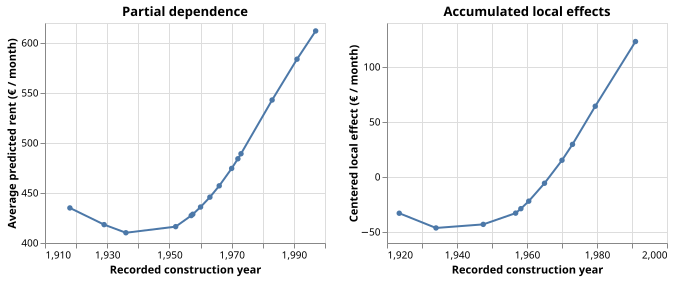

In [9]:
profile_predictors = train.select(
    "area", "yearc", "good_location", "top_location", "bath", "kitchen", "cheating")
profile = mb.prediction_profile(session.model, profile_predictors, "yearc",
    points=18, retain_ice=False)
ale = mb.accumulated_local_effect(session.model, profile_predictors, "yearc", bins=12)
pd_rows = profile.to_frame(output="polars")
ale_rows = ale.to_frame(output="polars")
pd_chart = alt.Chart(pd_rows).mark_line(point=True).encode(
    x=alt.X("grid:Q", title="Recorded construction year"),
    y=alt.Y("average_prediction:Q", title="Average predicted rent (€ / month)",
            scale=alt.Scale(zero=False)),
).properties(title="Partial dependence", width=280, height=220)
ale_chart = alt.Chart(ale_rows).mark_line(point=True).encode(
    x=alt.X("grid:Q", title="Recorded construction year"),
    y=alt.Y("effect:Q", title="Centered local effect (€ / month)"),
    tooltip=["lower:Q", "upper:Q", "n:Q"],
).properties(title="Accumulated local effects", width=280, height=220)
display(alt.hconcat(pd_chart, ale_chart).resolve_scale(y="independent"))

In [10]:
profile_points = pd_rows.filter(
    pl.col("grid").is_in([1918.0, 1929.0, 1936.0, 1997.0])
).with_columns(pl.col("grid").cast(pl.Int64).alias("year")).select(
    "year", "average_prediction", "support_fraction_far")
display(table(profile_points, title="Support at selected construction years",
    subtitle="Predicted euros/month and fraction of replaced rows far from joint support; lower support fraction is better",
    stub="year", stubhead="Recorded year",
    labels={"average_prediction": "Average prediction (€)",
            "support_fraction_far": "Fraction far"},
    formats={"average_prediction": 1, "support_fraction_far": 3},
    notes=("The 1918 support fraction is computed from fitted predictors only; an unused year-derived indicator would inflate it.",
           "The diagnostic uses a linear support model and can miss nonlinear or categorical gaps.")))

GT(_tbl_data=shape: (4, 3)
┌──────┬────────────────────┬──────────────────────┐
│ year ┆ average_prediction ┆ support_fraction_far │
│ ---  ┆ ---                ┆ ---                  │
│ i64  ┆ f64                ┆ f64                  │
╞══════╪════════════════════╪══════════════════════╡
│ 1918 ┆ 435.062392         ┆ 0.073428             │
│ 1929 ┆ 418.367058         ┆ 0.0                  │
│ 1936 ┆ 410.252389         ┆ 0.0                  │
│ 1997 ┆ 612.051331         ┆ 0.151318             │
└──────┴────────────────────┴──────────────────────┘, _body=<great_tables._gt_data.Body object at 0x10afecdd0>, _boxhead=Boxhead([ColInfo(var='year', type=<ColInfoTypeEnum.stub: 2>, column_label='year', column_align='right', column_width=None, stub_level=0), ColInfo(var='average_prediction', type=<ColInfoTypeEnum.default: 1>, column_label='Average prediction (€)', column_align='right', column_width=None, stub_level=None), ColInfo(var='support_fraction_far', type=<ColInfoTypeEnum.default: 1>, column_label='Fraction far', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10afcf770>, _spanners=Spanners([]), _heading=Heading(title='Support at selected construction years', subtitle='Predicted euros/month and fraction of replaced rows far from joint support; lower support fraction is better', preheader=None), _stubhead='Recorded year', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10db0df70>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db0cc20>, _source_notes=['The 1918 support fraction is computed from fitted predictors only; an unused year-derived indicator would inflate it.', 'The diagnostic uses a linear support model and can miss nonlinear or categorical gaps.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10db0c290>, _formats=[<great_tables._gt_data.FormatInfo object at 0x114ca7110>, <great_tables._gt_data.FormatInfo object at 0x10db6f350>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10db6f410>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo

The fitted mean falls from roughly €435 at the `1918` code to €410 around 1936, then rises toward €612 at 1997. ALE also declines over the two oldest occupied intervals, so global replacement alone does not create the fitted dip. About 7% of the all-apartment replacements at `1918` are flagged far after restricting the diagnostic to fitted predictors, so simple linear joint-support failure does not account for the dip. The distribution has 355 development apartments at exactly 1918 and 298 at 1957.5; these repeated values, including a fractional year, suggest that `yearc` may encode grouped periods. That is an inference from the values, not a documented recoding rule. Older apartments also differ in size, location grade and heating. The dip motivates tests of alternative explanations; by itself it does not establish an omitted cause.

In [11]:
eras = train.with_columns(
    pl.when(pl.col("yearc") == 1918).then(pl.lit("1918 code"))
      .when(pl.col("yearc") < 1950).then(pl.lit("1919–49"))
      .when(pl.col("yearc") < 1970).then(pl.lit("1950–69"))
      .when(pl.col("yearc") < 1990).then(pl.lit("1970–89"))
      .otherwise(pl.lit("1990–97")).alias("period")
)
support = eras.group_by("period").agg(
    pl.len().alias("apartments"), pl.col("district").n_unique().alias("districts"),
    pl.col("area").mean().alias("area_m2"),
    (1 - pl.col("cheating").mean()).alias("without_heating"),
).sort("period")
display(table(support, title="Observed support by construction period",
    subtitle="Development apartments, distinct districts, mean area (m²), and share without central heating",
    stub="period", stubhead="Recorded period",
    labels={"apartments": "Apartments", "districts": "Districts",
            "area_m2": "Mean area (m²)", "without_heating": "No heating share"},
    formats={"area_m2": 1, "without_heating": 3},
    notes=("Period bands are descriptive; the model uses recorded year, not these bands.",)))

GT(_tbl_data=shape: (5, 5)
┌───────────┬────────────┬───────────┬───────────┬─────────────────┐
│ period    ┆ apartments ┆ districts ┆ area_m2   ┆ without_heating │
│ ---       ┆ ---        ┆ ---       ┆ ---       ┆ ---             │
│ str       ┆ u32        ┆ u32       ┆ f64       ┆ f64             │
╞═══════════╪════════════╪═══════════╪═══════════╪═════════════════╡
│ 1918 code ┆ 355        ┆ 104       ┆ 81.715493 ┆ 0.321127        │
│ 1919–49   ┆ 362        ┆ 120       ┆ 73.455801 ┆ 0.196133        │
│ 1950–69   ┆ 997        ┆ 196       ┆ 63.107322 ┆ 0.058175        │
│ 1970–89   ┆ 596        ┆ 190       ┆ 63.087248 ┆ 0.008389        │
│ 1990–97   ┆ 155        ┆ 99        ┆ 66.509677 ┆ 0.0             │
└───────────┴────────────┴───────────┴───────────┴─────────────────┘, _body=<great_tables._gt_data.Body object at 0x114ca6780>, _boxhead=Boxhead([ColInfo(var='period', type=<ColInfoTypeEnum.stub: 2>, column_label='period', column_align='left', column_width=None, stub_level=0), ColInfo(var='apartments', type=<ColInfoTypeEnum.default: 1>, column_label='Apartments', column_align='right', column_width=None, stub_level=None), ColInfo(var='districts', type=<ColInfoTypeEnum.default: 1>, column_label='Districts', column_align='right', column_width=None, stub_level=None), ColInfo(var='area_m2', type=<ColInfoTypeEnum.default: 1>, column_label='Mean area (m²)', column_align='right', column_width=None, stub_level=None), ColInfo(var='without_heating', type=<ColInfoTypeEnum.default: 1>, column_label='No heating share', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10d82bad0>, _spanners=Spanners([]), _heading=Heading(title='Observed support by construction period', subtitle='Development apartments, distinct districts, mean area (m²), and share without central heating', preheader=None), _stubhead='Recorded period', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10db6fb00>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db6fd70>, _source_notes=['Period bands are descriptive; the model uses recorded year, not these bands.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10db6f230>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10d7a78c0>, <great_tables._gt_data.FormatInfo object at 0x10db6ff80>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10db6f8f0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, cat

## Monotonicity and period coding

Two competing explanations are recorded as hypotheses: a newer-building premium with an old-period exception, and a data-code explanation concentrated at 1918. A monotone year term tests whether the exception is needed for prediction. Adding `old_1918` to that term asks whether a separate oldest-code premium improves it. A linear year plus that indicator tests whether the smooth was only hiding one jump. All comparisons use the same development folds and the tuned step count of 61 iterations.

In [12]:
session.run("hypothesis", variable="yearc", role="building-period and quality proxy",
    statement="Rent generally rises with newer construction, apart from a possible older-building premium.",
    would_count_against="A monotone year term predicts as well on new-district folds.")
session.run("hypothesis", variable="old_1918", role="possible period code",
    statement="The oldest-year departure may be concentrated at the heaped 1918 code.",
    would_count_against="An explicit 1918 indicator does not improve a monotone or linear year model.")
current = session.spec
period_tests = session.run("compare", candidates={
    "monotone year": current.replace("bbs(yearc)",
        'bmono(yearc, constraint="increasing")'),
    "monotone plus 1918": current.replace("bbs(yearc)",
        'bmono(yearc, constraint="increasing") + bols(old_1918)'),
    "linear plus 1918": current.replace("bbs(yearc)",
        "bols(yearc) + bols(old_1918)"),
})
period_rows = pl.DataFrame([{
    "candidate": row["specification"], "mse": row["out-of-fold risk"],
    "change": row["change"], "se": row["change se"],
} for row in period_tests.value])
display(table(period_rows, title="Construction-year alternatives",
    subtitle="New-district development-fold MSE and change from incumbent, euros²; lower is better",
    stub="candidate", stubhead="Candidate", better={"mse": "min"},
    labels={"mse": "MSE", "change": "Change", "se": "Paired SE"}, decimals=1,
    notes=("All candidates are fitted at the incumbent's 61 iterations on the same folds.",
           "The standard errors are descriptive after this search.")))

GT(_tbl_data=shape: (4, 4)
┌────────────────────┬──────────────┬────────────┬────────────┐
│ candidate          ┆ mse          ┆ change     ┆ se         │
│ ---                ┆ ---          ┆ ---        ┆ ---        │
│ str                ┆ f64          ┆ f64        ┆ f64        │
╞════════════════════╪══════════════╪════════════╪════════════╡
│ current            ┆ 18615.140114 ┆ 0.0        ┆ 0.0        │
│ monotone year      ┆ 18632.567901 ┆ 17.427788  ┆ 51.18843   │
│ monotone plus 1918 ┆ 18639.797222 ┆ 24.657109  ┆ 39.1508    │
│ linear plus 1918   ┆ 19284.884466 ┆ 669.744352 ┆ 135.351577 │
└────────────────────┴──────────────┴────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10bcb8e00>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None, stub_level=0), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='Change', column_align='right', column_width=None, stub_level=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10d840770>, _spanners=Spanners([]), _heading=Heading(title='Construction-year alternatives', subtitle='New-district development-fold MSE and change from incumbent, euros²; lower is better', preheader=None), _stubhead='Candidate', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10db0e3f0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db6fb30>, _source_notes=["All candidates are fitted at the incumbent's 61 iterations on the same folds.", 'The standard errors are descriptive after this search.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10db6eff0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10db0fbf0>, <great_tables._gt_data.FormatInfo object at 0x10db6eed0>, <great_tables._gt_data.FormatInfo object at 0x10db6e810>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10db8c770>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='valu

The monotone fit is only about 17 ± 51 euros² worse than the smooth: this search does not establish that the old-period dip is necessary. Adding a 1918 indicator to the monotone fit does not improve it. Replacing the smooth year term by a linear year term plus the 1918 indicator is roughly 670 ± 135 euros² worse, so the year structure is broader than a single repeated code. The accepted smooth year term is kept, and its old-period dip is treated as uncertain.

## Residual interaction leads

`interaction_screen` ranks pairs of predictors by the residual MSE of the accepted model that a pair-specific fit removes on a half split of the development data. Its top-ranked pair is area × central heating; the area–year pair proposed by the tree pre-scan does not appear among its first five. The comparisons test a tensor-product smooth and a depth-2 tree on the area–year pair. Because apartments without central heating are concentrated in the oldest periods and absent among the newest, a year-by-heating term tests whether heating explains the old-period pattern; its support is inspected before adoption is considered.

In [13]:
leads = session.run("interaction_screen")
lead_rows = pl.DataFrame([{
    "pair": f"{row['left']} × {row['right']}", "screen_gain": row["removed"],
} for row in leads.summary["top_pairs"][:5]])
display(table(lead_rows, title="Residual interaction screen",
    subtitle="Half-split residual MSE removed, euros²; screening signal only, higher is stronger",
    stub="pair", stubhead="Pair", labels={"screen_gain": "Screen signal"},
    better={"screen_gain": "max"}, decimals=1,
    notes=("This ranking is a screening signal; fold-tested candidates are in the table Complete interaction specifications.",)))

interaction_tests = session.run("compare", candidates={
    "area–year tensor": current + " + bbs(area) %X% bbs(yearc)",
    "year by heating": current + " + bbs(yearc, by=cheating)",
    "shallow area–year tree": current + " + btree(area, yearc, maxdepth=2)",
})
interaction_rows = pl.DataFrame([{
    "candidate": row["specification"], "mse": row["out-of-fold risk"],
    "change": row["change"], "se": row["change se"],
} for row in interaction_tests.value])
display(table(interaction_rows, title="Complete interaction specifications",
    subtitle="New-district development-fold MSE and change from additive model, euros²; lower is better",
    stub="candidate", stubhead="Candidate", better={"mse": "min"},
    labels={"mse": "MSE", "change": "Change", "se": "Paired SE"}, decimals=1,
    notes=("The tensor and tree test the area–year pair proposed by the tree pre-scan; the heating term tests a domain hypothesis.",
           "The apparent 1918 premium remains a conditional association, not a heating effect.")))

GT(_tbl_data=shape: (5, 2)
┌─────────────────────────┬─────────────┐
│ pair                    ┆ screen_gain │
│ ---                     ┆ ---         │
│ str                     ┆ f64         │
╞═════════════════════════╪═════════════╡
│ area × cheating         ┆ 158.07388   │
│ old_1918 × bath         ┆ 143.163588  │
│ good_location × kitchen ┆ 49.93101    │
│ old_1918 × kitchen      ┆ 34.331142   │
│ old_1918 × cheating     ┆ 18.184374   │
└─────────────────────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x10db0f440>, _boxhead=Boxhead([ColInfo(var='pair', type=<ColInfoTypeEnum.stub: 2>, column_label='pair', column_align='left', column_width=None, stub_level=0), ColInfo(var='screen_gain', type=<ColInfoTypeEnum.default: 1>, column_label='Screen signal', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10db6f4a0>, _spanners=Spanners([]), _heading=Heading(title='Residual interaction screen', subtitle='Half-split residual MSE removed, euros²; screening signal only, higher is stronger', preheader=None), _stubhead='Pair', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x114ca7e90>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db8d4f0>, _source_notes=['This ranking is a screening signal; fold-tested candidates are in the table Complete interaction specifications.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10db8d5e0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x114ca6a80>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10db8d610>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', value='#D3D3D3'), table_border_bottom_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_bottom_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_bottom_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), ta

GT(_tbl_data=shape: (4, 4)
┌────────────────────────┬──────────────┬─────────────┬────────────┐
│ candidate              ┆ mse          ┆ change      ┆ se         │
│ ---                    ┆ ---          ┆ ---         ┆ ---        │
│ str                    ┆ f64          ┆ f64         ┆ f64        │
╞════════════════════════╪══════════════╪═════════════╪════════════╡
│ current                ┆ 18615.140114 ┆ 0.0         ┆ 0.0        │
│ area–year tensor       ┆ 18542.524844 ┆ -72.61527   ┆ 194.938428 │
│ year by heating        ┆ 18570.985788 ┆ -44.154326  ┆ 14.765109  │
│ shallow area–year tree ┆ 19927.516112 ┆ 1312.375998 ┆ 590.62867  │
└────────────────────────┴──────────────┴─────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10db0cbc0>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None, stub_level=0), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='Change', column_align='right', column_width=None, stub_level=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10d843d40>, _spanners=Spanners([]), _heading=Heading(title='Complete interaction specifications', subtitle='New-district development-fold MSE and change from additive model, euros²; lower is better', preheader=None), _stubhead='Candidate', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10db0f350>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db0f260>, _source_notes=['The tensor and tree test the area–year pair proposed by the tree pre-scan; the heating term tests a domain hypothesis.', 'The apparent 1918 premium remains a conditional association, not a heating effect.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10db0e120>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10db0fad0>, <great_tables._gt_data.FormatInfo object at 0x10db8d790>, <great_tables._gt_data.FormatInfo object at 0x10db8dbb0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10db8f950>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo

The area–year tensor improves MSE by about 73 ± 195 euros², too unstable for adoption; the shallow tree worsens it. The heating interaction improves MSE by about 44 ± 15 euros², about three paired SEs and so above the two-SE threshold, but it changes the fold root mean squared error (RMSE, the square root of MSE, in euros per month) by only about €0.16/month. In the development sample, 32% of the 1918-code apartments lack central heating, while none of the 1990–97 apartments do, so the term's curve for recent unheated apartments extrapolates beyond observed combinations. The interaction is not added: its gain is small and part of its fitted curve has no observed support. None of the measured alternatives identifies a single unobserved factor behind the dip; the selected curve is a reason for further tests.

## A smaller accepted model

In the table "Terms in the accepted smooth model", the premium-bathroom indicator `bath` has the smallest gain relative to its standard error (about 77 ± 89 euros²). Removing bathroom and kitchen are compared separately. `adopt(..., simplification_se=2)` accepts a smaller model when its fold error increase stays within two paired standard errors; this is a parsimony preference and does not test equivalence.

In [14]:
simplifications = session.run("compare", candidates={
    "drop bath": current.replace(" + bols(bath)", ""),
    "drop kitchen": current.replace(" + bols(kitchen)", ""),
})
simple_rows = pl.DataFrame([{
    "candidate": row["specification"], "mse": row["out-of-fold risk"],
    "change": row["change"], "se": row["change se"],
} for row in simplifications.value])
display(table(simple_rows, title="One-term reductions",
    subtitle="New-district development-fold MSE and change, euros²; lower is better",
    stub="candidate", stubhead="Candidate", better={"mse": "min"},
    labels={"mse": "MSE", "change": "Change", "se": "Paired SE"}, decimals=1,
    notes=("Positive change means the smaller model predicts worse on these folds.",
           "The two-SE tolerance is a descriptive parsimony rule, not an equivalence test.")))

GT(_tbl_data=shape: (3, 4)
┌──────────────┬──────────────┬────────────┬────────────┐
│ candidate    ┆ mse          ┆ change     ┆ se         │
│ ---          ┆ ---          ┆ ---        ┆ ---        │
│ str          ┆ f64          ┆ f64        ┆ f64        │
╞══════════════╪══════════════╪════════════╪════════════╡
│ current      ┆ 18615.140114 ┆ 0.0        ┆ 0.0        │
│ drop bath    ┆ 18691.923984 ┆ 76.783871  ┆ 89.126747  │
│ drop kitchen ┆ 18971.705995 ┆ 356.565881 ┆ 129.288024 │
└──────────────┴──────────────┴────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10db6f440>, _boxhead=Boxhead([ColInfo(var='candidate', type=<ColInfoTypeEnum.stub: 2>, column_label='candidate', column_align='left', column_width=None, stub_level=0), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='change', type=<ColInfoTypeEnum.default: 1>, column_label='Change', column_align='right', column_width=None, stub_level=None), ColInfo(var='se', type=<ColInfoTypeEnum.default: 1>, column_label='Paired SE', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10db6f740>, _spanners=Spanners([]), _heading=Heading(title='One-term reductions', subtitle='New-district development-fold MSE and change, euros²; lower is better', preheader=None), _stubhead='Candidate', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10db8e7e0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db8f0b0>, _source_notes=['Positive change means the smaller model predicts worse on these folds.', 'The two-SE tolerance is a descriptive parsimony rule, not an equivalence test.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10db8f500>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10db8f5f0>, <great_tables._gt_data.FormatInfo object at 0x10db8f320>, <great_tables._gt_data.FormatInfo object at 0x10db8edb0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10db8dc10>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_bord

Dropping bath costs about 77 ± 89 euros² and meets the stated parsimony tolerance. Dropping kitchen costs about 357 ± 129 euros², so it is retained. The final specification keeps a linear area term, a smooth construction-year term, location quality, kitchen quality and central heating. The smaller model is retuned instead of reusing the previous stopping iteration.

In [15]:
session.run("adopt", comparison_id=simplifications.evidence_id,
            candidate="drop bath", simplification_se=2.0)
final_tuning = session.run("tune", start=100)
final_cv = session.run("evaluate", mstop=session.mstop)
print("Accepted specification:", session.spec)
print("Tuned mstop:", session.mstop)
print(f"Development-fold MSE: {final_cv.summary['score']:.1f} euros²")
print("Whole-workflow native fits charged:", session.state()["budget"]["fit_charges"])
print("Action sequence:", " → ".join(row.action for row in session.evidence))

Accepted specification: bols(area) + bbs(yearc) + bols(good_location) + bols(top_location) + bols(kitchen) + bols(cheating)
Tuned mstop: 56
Development-fold MSE: 18683.9 euros²
Whole-workflow native fits charged: 166
Action sequence: hypothesis → classify → column_screen → pre_scan → set_spec → tune → compare → adopt → tune → autospec → term_report → hypothesis → hypothesis → compare → interaction_screen → compare → compare → adopt → tune → evaluate


## One-time district test

The selected model and the separately tuned linear baseline are frozen, that is, their specifications and stopping iterations are fixed, before either sees test outcomes. `final_evaluate` reads the 67 held-out districts once for the selected specification. The baseline's predictions were fixed on development data; its error is calculated in this same reporting step. No later model choice uses these results.

In [16]:
session.run("freeze")
final_test = session.run("final_evaluate", data=test)
linear_pred = baseline_model.predict(test, type="response")
linear_mse = pl.DataFrame({"observed": test["rent"],
                           "predicted": pl.Series(linear_pred)}).select(
    ((pl.col("observed") - pl.col("predicted")) ** 2).mean()).item()
test_rows = pl.DataFrame([
    {"model": "Tuned linear baseline", "mse": linear_mse,
     "rmse": math.sqrt(linear_mse)},
    {"model": "Selected smaller smooth model", "mse": final_test.summary["score"],
     "rmse": math.sqrt(final_test.summary["score"])},
])
display(table(test_rows, title="Untouched-district prediction",
    subtitle="617 apartments in 67 held-out districts; MSE in euros², RMSE in euros/month; lower is better",
    stub="model", stubhead="Frozen model", better={"mse": "min", "rmse": "min"},
    labels={"mse": "MSE", "rmse": "RMSE"}, decimals=1,
    notes=("Both specifications and stopping iterations were fixed using development districts.",
           "This one district split is a predictive check, not a confidence interval for the search procedure.")))

GT(_tbl_data=shape: (2, 3)
┌───────────────────────────────┬──────────────┬────────────┐
│ model                         ┆ mse          ┆ rmse       │
│ ---                           ┆ ---          ┆ ---        │
│ str                           ┆ f64          ┆ f64        │
╞═══════════════════════════════╪══════════════╪════════════╡
│ Tuned linear baseline         ┆ 21041.358205 ┆ 145.056397 │
│ Selected smaller smooth model ┆ 20526.963292 ┆ 143.27234  │
└───────────────────────────────┴──────────────┴────────────┘, _body=<great_tables._gt_data.Body object at 0x10db6ede0>, _boxhead=Boxhead([ColInfo(var='model', type=<ColInfoTypeEnum.stub: 2>, column_label='model', column_align='left', column_width=None, stub_level=0), ColInfo(var='mse', type=<ColInfoTypeEnum.default: 1>, column_label='MSE', column_align='right', column_width=None, stub_level=None), ColInfo(var='rmse', type=<ColInfoTypeEnum.default: 1>, column_label='RMSE', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10afcef60>, _spanners=Spanners([]), _heading=Heading(title='Untouched-district prediction', subtitle='617 apartments in 67 held-out districts; MSE in euros², RMSE in euros/month; lower is better', preheader=None), _stubhead='Frozen model', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10db8e450>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10db8f020>, _source_notes=['Both specifications and stopping iterations were fixed using development districts.', 'This one district split is a predictive check, not a confidence interval for the search procedure.'], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10db8d7f0>, _formats=[<great_tables._gt_data.FormatInfo object at 0x10db8e570>, <great_tables._gt_data.FormatInfo object at 0x10db8e3f0>], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10db8f0b0>], _col_merge=[], _transforms=[], _options=Options(table_id=OptionsInfo(scss=False, category='table', type='value', value=None), table_caption=OptionsInfo(scss=False, category='table', type='value', value=None), table_width=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_layout=OptionsInfo(scss=True, category='table', type='value', value='fixed'), table_margin_left=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_margin_right=OptionsInfo(scss=True, category='table', type='px', value='auto'), table_background_color=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_additional_css=OptionsInfo(scss=False, category='table', type='values', value=[]), table_font_names=OptionsInfo(scss=False, category='table', type='values', value=['-apple-system', 'BlinkMacSystemFont', 'Segoe UI', 'Roboto', 'Oxygen', 'Ubuntu', 'Cantarell', 'Helvetica Neue', 'Fira Sans', 'Droid Sans', 'Arial', 'sans-serif']), table_font_size=OptionsInfo(scss=True, category='table', type='px', value='16px'), table_font_weight=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_style=OptionsInfo(scss=True, category='table', type='value', value='normal'), table_font_color=OptionsInfo(scss=True, category='table', type='value', value='#333333'), table_font_color_light=OptionsInfo(scss=True, category='table', type='value', value='#FFFFFF'), table_border_top_include=OptionsInfo(scss=False, category='table', type='boolean', value=True), table_border_top_style=OptionsInfo(scss=True, category='table', type='value', value='solid'), table_border_top_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_top_color=OptionsInfo(scss=True, category='table', type='value', value='#A8A8A8'), table_border_right_style=OptionsInfo(scss=True, category='table', type='value', value='none'), table_border_right_width=OptionsInfo(scss=True, category='table', type='px', value='2px'), table_border_right_color=OptionsInfo(scss=True, category='table', type='value', valu

The selected model's test RMSE is about €143.3/month versus €145.1/month for the tuned linear baseline, a small improvement on this one district split. It does not establish that the detailed old-building dip or any interaction generalizes. The year curve is conditional on a coarse location grade and recorded amenities; unmeasured renovation, exact location and period coding remain plausible explanations. `rentsqm` was excluded because it is derived from rent, and the district effect was excluded because the target districts were unseen. The same procedure would need repeated district holdouts before claiming a stable advantage over a simpler pricing rule.

Related cases model [spatial district effects](munich_rents.ipynb) and [the conditional rent distribution](munich_rents_distributional.ipynb). In this case, small gains in the interaction comparison and limited support in the year-curve checks restrict the interpretation of the selected year shape.